In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Superstore_Cleaned.csv")

print(df.head())

        Ship Mode    Segment        Country             City       State  \
0    Second Class   Consumer  United States        Henderson    Kentucky   
1    Second Class   Consumer  United States        Henderson    Kentucky   
2    Second Class  Corporate  United States      Los Angeles  California   
3  Standard Class   Consumer  United States  Fort Lauderdale     Florida   
4  Standard Class   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region         Category Sub-Category     Sales  Quantity  \
0        42420  South        Furniture    Bookcases  261.9600         2   
1        42420  South        Furniture       Chairs  731.9400         3   
2        90036   West  Office Supplies       Labels   14.6200         2   
3        33311  South        Furniture       Tables  957.5775         5   
4        33311  South  Office Supplies      Storage   22.3680         2   

   Discount    Profit  
0      0.00   41.9136  
1      0.00  219.5820  
2      0.00    6.871

In [2]:
print("Dataset Shape:", df.shape)

Dataset Shape: (9977, 13)


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9977 entries, 0 to 9976
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9977 non-null   object 
 1   Segment       9977 non-null   object 
 2   Country       9977 non-null   object 
 3   City          9977 non-null   object 
 4   State         9977 non-null   object 
 5   Postal Code   9977 non-null   int64  
 6   Region        9977 non-null   object 
 7   Category      9977 non-null   object 
 8   Sub-Category  9977 non-null   object 
 9   Sales         9977 non-null   float64
 10  Quantity      9977 non-null   int64  
 11  Discount      9977 non-null   float64
 12  Profit        9977 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1013.4+ KB
None


In [4]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [5]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9977.000000,9977.000000,9977.000000,9977.000000,9977.00000
mean,55154.964117,230.148902,3.790719,0.156278,28.69013
std,32058.266816,623.721409,2.226657,0.206455,234.45784
min,1040.000000,0.444000,1.000000,0.000000,-6599.97800
25%,23223.000000,17.300000,2.000000,0.000000,1.72620
50%,55901.000000,54.816000,3.000000,0.200000,8.67100
75%,90008.000000,209.970000,5.000000,0.200000,29.37200
max,99301.000000,22638.480000,14.000000,0.800000,8399.97600


In [6]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

print("Total sales:",round(total_sales, 2))
print("Total profit:", round(total_profit, 2))

Total sales: 2296195.59
Total profit: 286241.42


In [7]:
profit_mergin = (total_profit / total_sales) * 100

print("Overall Profit Margin: ", round(profit_mergin, 2), "%")

Overall Profit Margin:  12.47 %


In [8]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

Category
Furniture          741306.3133
Office Supplies    718735.2440
Technology         836154.0330
Name: Sales, dtype: float64


In [9]:
category_profit = df.groupby("Category")["Profit"].sum()

print(category_profit)

Category
Furniture           18421.8137
Office Supplies    122364.6608
Technology         145454.9481
Name: Profit, dtype: float64


In [10]:
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum()

print(subcategory_sales.sort_values(ascending=False))

Sub-Category
Phones         330007.0540
Chairs         327777.7610
Storage        223843.6080
Tables         206965.5320
Binders        203409.1690
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91683.0240
Paper           78224.1420
Supplies        46673.5380
Art             27107.0320
Envelopes       16476.4020
Labels          12444.9120
Fasteners        3024.2800
Name: Sales, dtype: float64


In [11]:
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum()

print(subcategory_profit.sort_values(ascending=False))

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          33944.2395
Binders        30228.0003
Chairs         26567.1278
Storage        21278.8264
Appliances     18138.0054
Furnishings    13052.7230
Envelopes       6964.1767
Art             6524.6118
Labels          5526.3820
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64


In [12]:
region_sales = df.groupby("Region")["Sales"].sum()

print(region_sales.sort_values(ascending=False))

Region
West       725255.6365
East       678435.1960
Central    500782.8528
South      391721.9050
Name: Sales, dtype: float64


In [13]:
region_profit = df.groupby("Region")["Profit"].sum()

print(region_profit.sort_values(ascending=False))

Region
West       108329.8079
East        91506.3092
South       46749.4303
Central     39655.8752
Name: Profit, dtype: float64


In [14]:
segment_analysis = df.groupby("Segment")[["Sales", "Profit"]].sum()

print(segment_analysis.sort_values(by="Sales", ascending=False))

                    Sales       Profit
Segment                               
Consumer     1.160833e+06  134007.4413
Corporate    7.060701e+05   91954.9798
Home Office  4.292927e+05   60279.0015


In [15]:
segment_analysis["Profit_Margin"] = (
    segment_analysis["Profit"] / segment_analysis["Sales"] 
) * 100

print(segment_analysis.round(2))


                  Sales     Profit  Profit_Margin
Segment                                          
Consumer     1160832.77  134007.44          11.54
Corporate     706070.13   91954.98          13.02
Home Office   429292.68   60279.00          14.04


In [16]:
segment_analysis = df.groupby("Segment")[["Sales","Profit"]].sum()

segment_analysis = segment_analysis.sort_values(
    by="Sales",
    ascending=False
)
print(segment_analysis.round(2))

                  Sales     Profit
Segment                           
Consumer     1160832.77  134007.44
Corporate     706070.13   91954.98
Home Office   429292.68   60279.00


### The Consumer segment generate the
### highest sales and total profit among the three customer segment

In [17]:
state_analysis = df.groupby("State")[["Sales", "Profit"]].sum()

state_analysis = state_analysis.sort_values(
    by="Sales",
    ascending=False
)

print(state_analysis.round(2).head(10))

                  Sales    Profit
State                            
California    457576.27  76330.79
New York      310827.15  74015.46
Texas         170124.54 -25750.98
Washington    138560.81  33368.24
Pennsylvania  116496.36 -15565.40
Florida        89473.71  -3399.30
Illinois       80162.54 -12601.65
Ohio           77976.76 -16959.32
Michigan       75879.64  24428.09
Virginia       70636.72  18597.95


### California has the higest sales and profit among the states in our analysis

In [18]:
state_profit = df.groupby("State")["Profit"].sum()

print(state_profit.sort_values(ascending=False).head(5).round(2))

State
California    76330.79
New York      74015.46
Washington    33368.24
Michigan      24428.09
Virginia      18597.95
Name: Profit, dtype: float64


In [19]:
state_profit = df.groupby("State")["Profit"].sum()

loss_making_states = state_profit[state_profit < 0]
print(loss_making_states.sort_values().round(2))

State
Texas            -25750.98
Ohio             -16959.32
Pennsylvania     -15565.40
Illinois         -12601.65
North Carolina    -7490.91
Colorado          -6527.86
Tennessee         -5341.69
Arizona           -3427.92
Florida           -3399.30
Oregon            -1194.10
Name: Profit, dtype: float64


### Texas has the largest total loss, so it deserves further investigation. 
#### we should examine which products or subcategories are contributing to that loss

In [20]:
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum()

print("Top 5 Profitable subcategories:")
print(subcategory_profit.sort_values(ascending=False).head(5).round(2))

print("\nBottom 5 Subcategories:")
print(subcategory_profit.sort_values().head(5).round(2))

Top 5 Profitable subcategories:
Sub-Category
Copiers        55617.82
Phones         44515.73
Accessories    41936.64
Paper          33944.24
Binders        30228.00
Name: Profit, dtype: float64

Bottom 5 Subcategories:
Sub-Category
Tables      -17725.48
Bookcases    -3472.56
Supplies     -1189.10
Fasteners      949.52
Machines      3384.76
Name: Profit, dtype: float64


### Tables have the largest loss of all the subcategories. copiers generate the highest profit

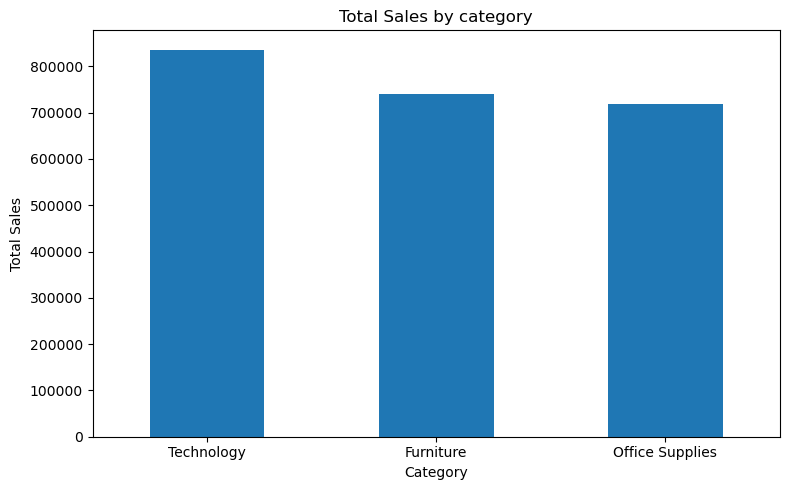

In [21]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

category_sales.plot(kind="bar", figsize=(8,5))

plt.title("Total Sales by category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### The Technology category generates the highest total sales, followed by future. Office Supplies generates the lowest sales among the three categories. The business should investigate which products and factors contribute to these difference in sales proformance

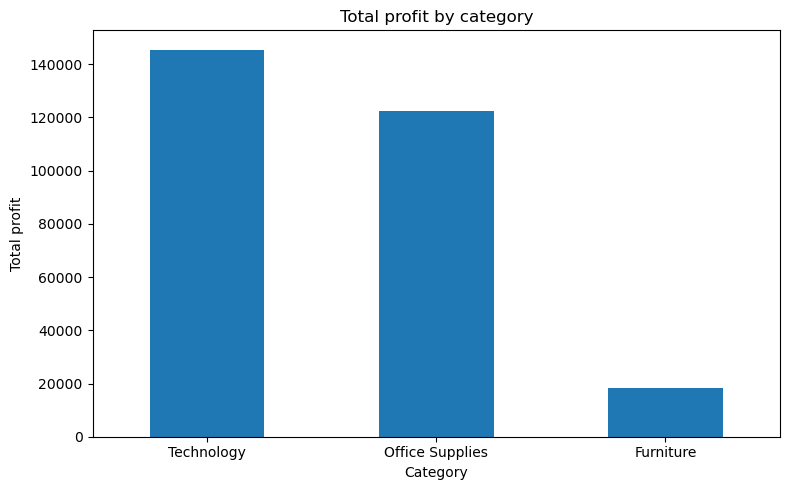

In [22]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

category_profit.plot(kind="bar", figsize=(8,5))

plt.title("Total profit by category")
plt.xlabel("Category")
plt.ylabel("Total profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Technology generates the highest total profit, followed by Office Supplies. Furniture generates the lowest total profit among the three categories.
### The business should investigate Furniture's profitability by examining its subcategories, discounts, and costs.

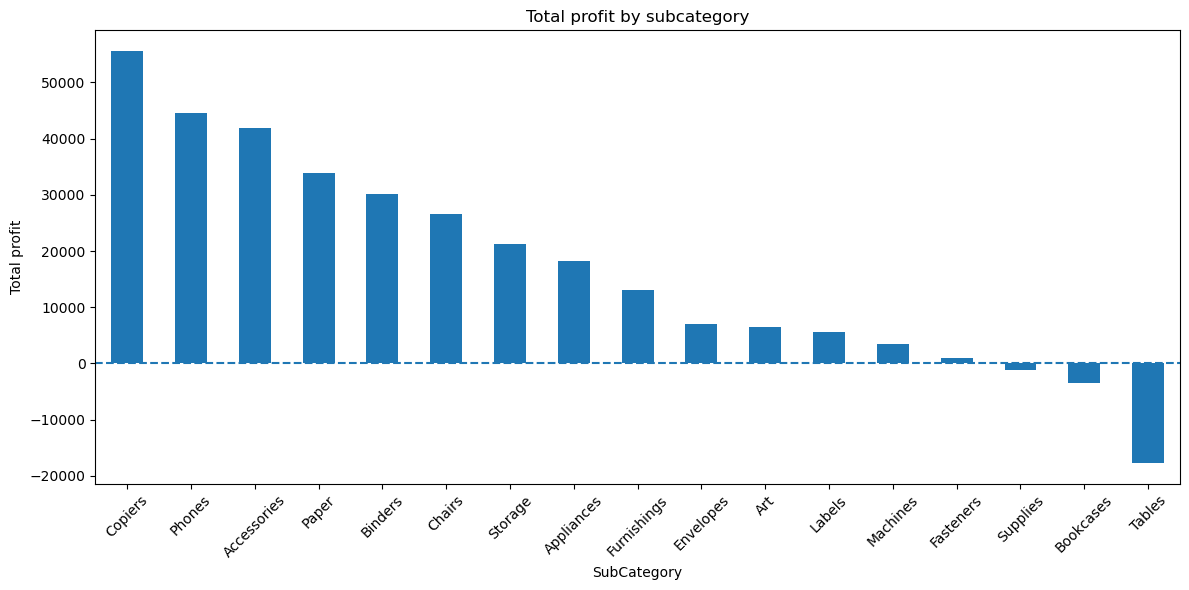

In [23]:
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False)

subcategory_profit.plot(kind="bar", figsize=(12, 6))

plt.title("Total profit by subcategory")
plt.xlabel("SubCategory")
plt.ylabel("Total profit")
plt.xticks(rotation=45)
plt.axhline(y=0, linestyle="--")
plt.tight_layout()
plt.show()

### Copiers generate the highest profit, followed by Phones and Accessories. Tables generate the largest loss, while Bookcases and Supplies also operate at a loss.
### The business should investigate the reasons for losses in Tables, Bookcases, and Supplies by reviewing discounts, pricing, and costs.

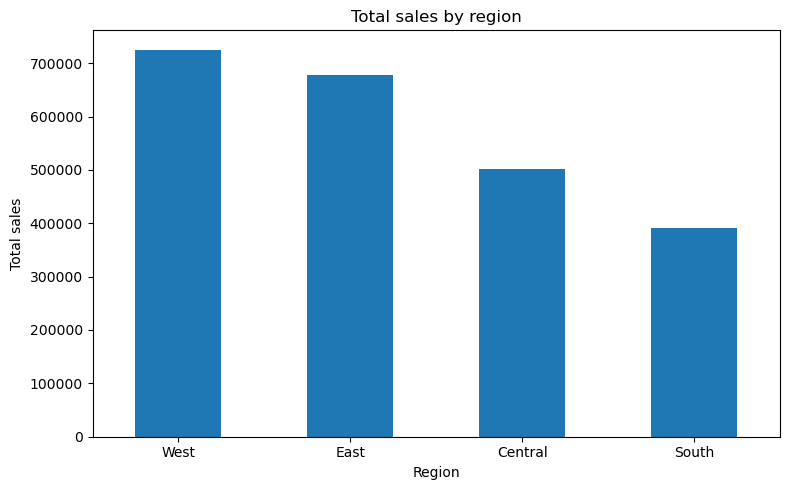

In [24]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

region_sales.plot(kind="bar", figsize=(8,5))

plt.title("Total sales by region")
plt.xlabel("Region")
plt.ylabel("Total sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### The West region generates the highest sales, followed by the East region. The South region generates the lowest sales.

### The business should investigate opportunities to increase sales in the South region while maintaining strong performance in the West and East regions.

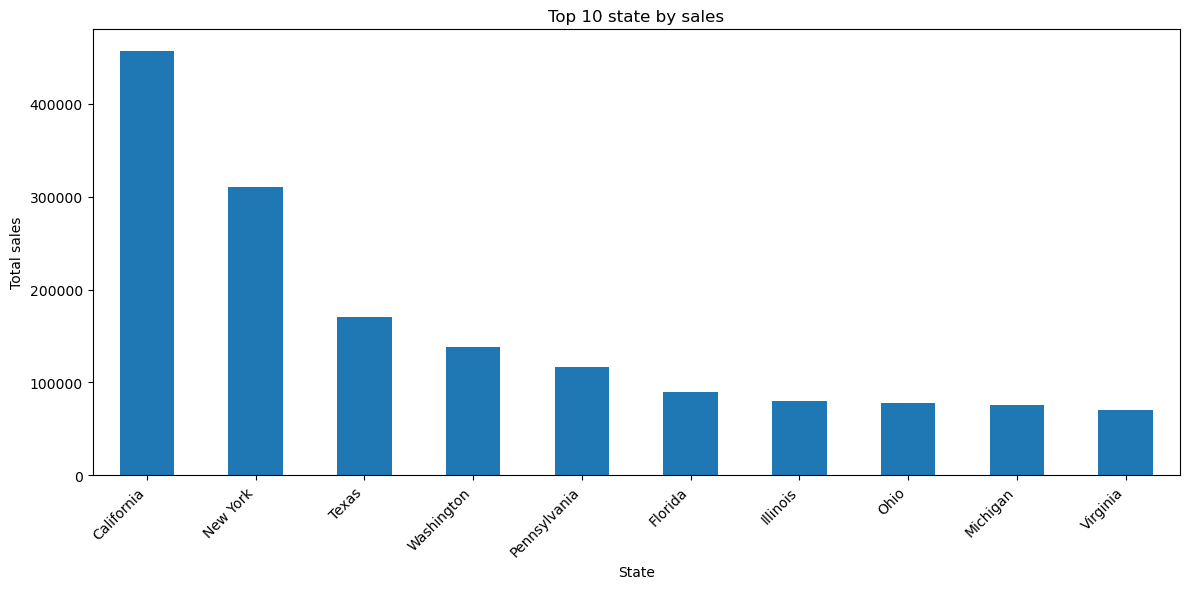

In [25]:
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10)

state_sales.plot(kind="bar", figsize=(12, 6))

plt.title("Top 10 state by sales")
plt.xlabel("State")
plt.ylabel("Total sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### California generates the highest sales, followed by New York and Texas. These states are important contributors to overall business revenue.

### The business should maintain its strong performance in these states while exploring opportunities to improve sales in lower-performing states.

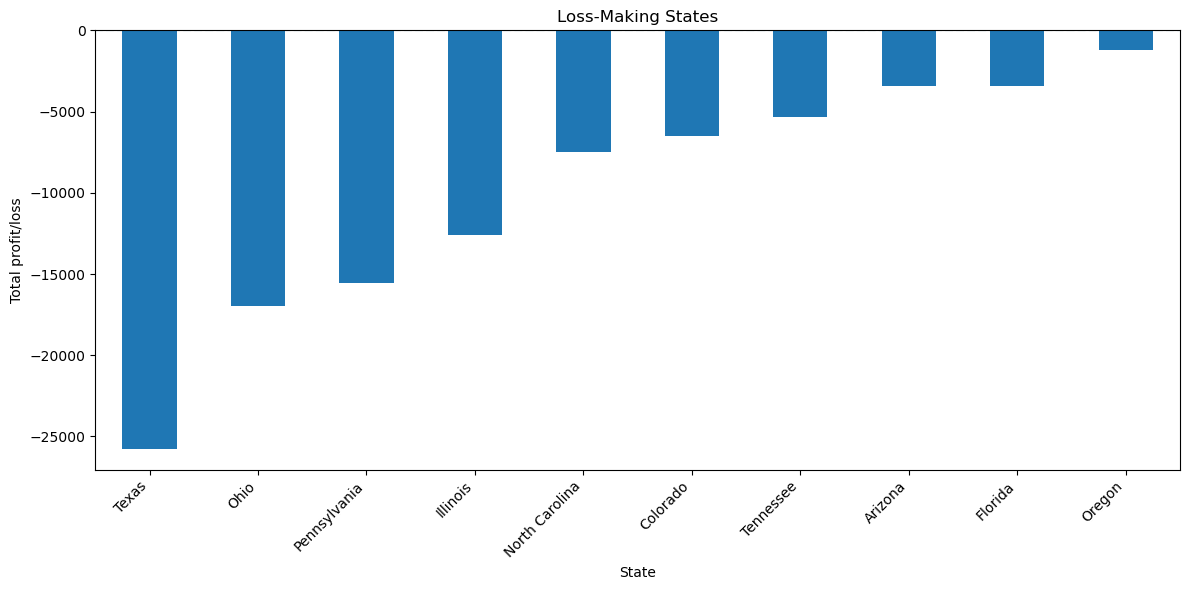

In [26]:
state_profit = df.groupby("State")["Profit"].sum()

loss_states = state_profit[state_profit < 0].sort_values()

loss_states.plot(kind="bar", figsize=(12, 6))

plt.title("Loss-Making States")
plt.xlabel("State")
plt.ylabel("Total profit/loss")
plt.xticks(rotation=45, ha="right")
plt.axhline(y=0, linestyle="--")
plt.tight_layout()
plt.show()

### Texas has the largest total loss, followed by Ohio and Pennsylvania. Several other states also report negative total profit.

### The business should investigate product discounts, pricing, and costs in these states to identify opportunities to improve profitability.

###  Final Business Summary — Superstore Sales Analysis

## Project Overview
This project analyzes Superstore sales and profitability using Python, Pandas, and Matplotlib to identify business trends and areas for improvement.

## Key Findings

1. Total sales were approximately 2.30 million, with total profit of approximately 286,241.
2. Technology generated the highest sales and profit among the three main categories.
3. Copiers, Phones, and Accessories were among the most profitable subcategories.
4. Tables generated the largest loss among the subcategories.
5. The West region recorded the highest sales, while the South region recorded the lowest.
6. California had the highest sales among all states.
7. Texas recorded the largest state-level loss, followed by Ohio and Pennsylvania.
8. The Consumer segment generated the highest sales and total profit, while Home Office had the highest profit margin.

## Business Recommendations

- Investigate losses in Tables, Bookcases, and Supplies.
- Review discounting, pricing, and costs in loss-making states.
- Explore opportunities to increase sales in the South region.
- Maintain strong performance in Technology and other profitable subcategories.
- Monitor profit margins across customer segments to support better business decisions.

## Tools Used
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Conclusion
This analysis demonstrates how Python can be used to explore sales data, measure profitability, identify business risks, and communicate actionable insights through visualizations.